# CSV, NumPy, Matplotlib, and Sensor Data

This notebook introduces a complete beginner data workflow: store observations in a CSV file, read the rows into Python, calculate numerical summaries, and draw a graph. The final section simulates temperature readings from an IoT sensor. It does not connect to a physical device.

The examples use the Python `csv` module, NumPy, and Matplotlib. Install the third-party libraries in the environment running Jupyter if they are not already available:

```text
pip install numpy matplotlib
```


## 1. From observations to information

Data analysis starts with observations and gives them a useful form. In this lesson, the process is: collect measurements, store rows with column headings, read the CSV, convert numeric text into numbers, summarize the values, draw a suitable graph, and describe only what the data supports.

A CSV file is plain text arranged in rows. Commas separate fields, and the first row commonly gives the column names. Values read from a CSV are text until the program converts them.


## 2. A first line graph

Matplotlib creates charts. A line graph is useful for measurements recorded in time order. `plot(x, y)` pairs each x-value with a y-value. A title, axis labels, and units make the graph readable. Markers identify the individual observations; the line helps show the sequence.


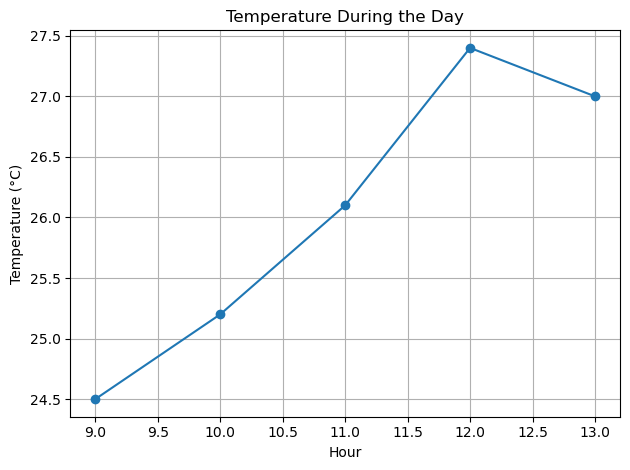

In [1]:
import matplotlib.pyplot as plt

hours = [9, 10, 11, 12, 13]
temperature_c = [24.5, 25.2, 26.1, 27.4, 27.0]

plt.plot(hours, temperature_c, marker="o")
plt.title("Temperature During the Day")
plt.xlabel("Hour")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.tight_layout()
plt.show()


The main plotting calls have distinct jobs: `plt.plot` draws the paired values, `plt.title` names the figure, `plt.xlabel` and `plt.ylabel` describe each axis, `plt.grid(True)` adds reading guides, and `plt.show()` displays the figure. Matplotlib can also make bar charts, scatter plots, and histograms; the chart type should match the kind of data and comparison.


## 3. Write sensor observations to CSV

Each row below contains a time and a temperature. `csv.writer` handles commas and quoting safely. `writerow` writes one row; `writerows` writes several rows. The header names make the columns easier to identify when the file is read again.

Running this cell creates `sensor_readings.csv` in the notebook's current working folder.


In [2]:
import csv
from pathlib import Path

readings = [
    ("09:00", 24.5),
    ("10:00", 25.2),
    ("11:00", 26.1),
    ("12:00", 27.4),
    ("13:00", 27.0),
]
sensor_csv = Path("sensor_readings.csv")

with sensor_csv.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["time", "temperature_c"])
    writer.writerows(readings)

print(f"Saved {len(readings)} readings to {sensor_csv.resolve()}")


Saved 5 readings to C:\Users\ashir\OneDrive\Desktop\Mirai\AKTU\Python\Python_fundas\DA\sensor_readings.csv


## 4. Read a CSV with column names

`csv.DictReader` reads each data row as a dictionary: the header becomes the keys and that row's fields become the values. The values are still strings. Convert the temperature field with `float()` before doing numerical calculations.


In [3]:
times = []
temperatures = []

with sensor_csv.open("r", newline="", encoding="utf-8") as file:
    reader = csv.DictReader(file)
    for row in reader:
        times.append(row["time"])
        temperatures.append(float(row["temperature_c"]))

print("Times:", times)
print("Temperatures (°C):", temperatures)


Times: ['09:00', '10:00', '11:00', '12:00', '13:00']
Temperatures (°C): [24.5, 25.2, 26.1, 27.4, 27.0]


The `newline=""` argument is the recommended way to open CSV files for the `csv` module. A wrong filename can cause `FileNotFoundError`; a heading that does not match the code can cause `KeyError`; attempting arithmetic on an unconverted numeric string will not work as intended. Check the file location, header spelling, and value types when diagnosing these errors.


## 5. Calculate a numerical summary

The mean is the sum divided by the number of readings. Python's `sum`, `len`, `min`, and `max` provide the basic operations. Check that the list is not empty before dividing or finding an extreme value.


In [4]:
if not temperatures:
    raise ValueError("The CSV contains no temperature readings")

mean_c = sum(temperatures) / len(temperatures)
print(f"Readings: {len(temperatures)}")
print(f"Mean: {mean_c:.2f} °C")
print(f"Minimum: {min(temperatures):.1f} °C")
print(f"Maximum: {max(temperatures):.1f} °C")


Readings: 5
Mean: 26.04 °C
Minimum: 24.5 °C
Maximum: 27.4 °C


## 6. Use NumPy for array calculations

NumPy arrays are designed for numerical work. Arithmetic is applied to each element, so adding `1` raises every temperature by one degree. NumPy also provides `mean`, `min`, and `max`. The calculations below should match the basic Python summary.


In [5]:
import numpy as np

temperature_array = np.array(temperatures)
print("Array:", temperature_array)
print("Mean:", round(float(np.mean(temperature_array)), 2), "°C")
print("Minimum:", np.min(temperature_array), "°C")
print("Maximum:", np.max(temperature_array), "°C")
print("Each value plus 1 °C:", temperature_array + 1)


Array: [24.5 25.2 26.1 27.4 27. ]
Mean: 26.04 °C
Minimum: 24.5 °C
Maximum: 27.4 °C
Each value plus 1 °C: [25.5 26.2 27.1 28.4 28. ]


## 7. Plot the CSV measurements

The time labels form an ordered sequence, so a line graph is suitable. A dashed horizontal line marks the mean and makes it easier to compare individual readings with the average.


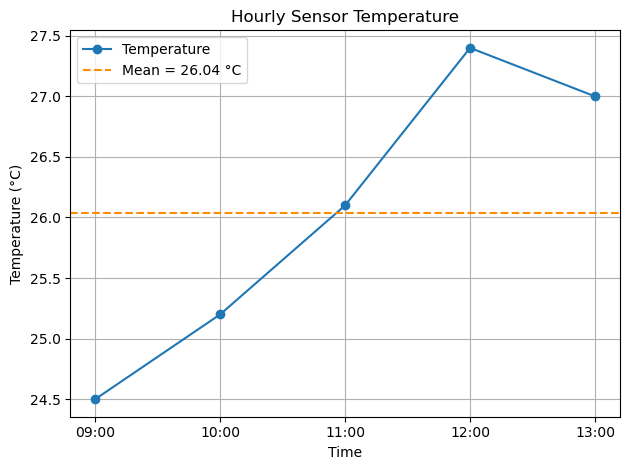

In [6]:
plt.plot(times, temperature_array, marker="o", label="Temperature")
plt.axhline(mean_c, linestyle="--", color="darkorange", label=f"Mean = {mean_c:.2f} °C")
plt.title("Hourly Sensor Temperature")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


This simulated series rises toward midday and then falls slightly. That statement describes these five observations only; it does not establish a general daily pattern. A graph reveals sequence and shape, while summary statistics describe the values. Both help communicate the data, and neither replaces checking whether the measurements, units, and observation period make sense.


## 8. The same pipeline in an IoT setting

An Internet of Things (IoT) sensor measures a physical quantity such as temperature. A real device or data logger could append timestamped measurements to a CSV file. This classroom example simulates those readings with a Python list, saves them, reads them back, calculates a mean, and plots them. The data and charting workflow is the same even though no physical sensor is connected.

For continuously arriving data, a real system would also need to decide how often to collect readings, where to store them, and how to handle missing or implausible measurements.


## Summary

CSV stores rows and headings as text. Python's `csv` module reads and writes those rows; numeric text must be converted before calculation. NumPy makes numerical summaries and element-wise arithmetic convenient. Matplotlib turns ordered measurements into a labeled graph. The interpretation should stay within what the observations actually show.
